In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import torch
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from torchvision import transforms

In [2]:
from sklearn.manifold import TSNE

In [3]:
import sys
import os
import cv2
from pathlib import Path
sys.path.insert(0, str(Path().resolve().parent.parent.parent))

# Now your imports will work
from assessment.vIAbility.data.dataset import build_labels, load_metadata, parse_video_name
from assessment.vIAbility.data.extract_FEMI_features import load_frames
from sklearn.model_selection import train_test_split
from config.config import SEED, PARAM_GRID, PATH_DATASET

/home/mvillota/anaconda3/envs/torch_cuda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
%cd ../../../

/home/mvillota/Documentos/Tesis/EmbryoDev_Assess


In [5]:
PATH_DATASET = Path(PATH_DATASET)/'Oslo_processed'
path_videos  = PATH_DATASET/'videos'
excel_path = PATH_DATASET/'Oslo_completo.xlsx'
features_path = PATH_DATASET/'features_resnet34'

In [6]:
class Resnet34Dataset:
    def __init__(self, files: list[str]):
        self.files  = files

    def __len__(self) -> int:
        return len(self.files)

    def __getitem__(self, idx: int):
        data = torch.load(self.files[idx], map_location="cpu", weights_only=False)
        filename = os.path.basename(self.files[idx]).split("_features.pt")[0]
        x    = data["embeddings"]  
        mask = data["mask"]         
        y    = data["label"]
        return filename, x, mask, y
    
    def all_labels(self):
        return [torch.load(f, map_location="cpu", weights_only=True)["label"].int() for f in self.files]

In [7]:
def plot_tsne(vis_dims, color = True, index = None, marker = 'o'):
    if color:
        if index is not None:
            colores = np.array(index)
        else:
            colores = np.arange(len(vis_dims))
    else:
        colores = 'blue'

    plt.figure(figsize=(12, 8))
    scatter = plt.scatter(
        vis_dims[:, 0], 
        vis_dims[:, 1], 
        c=colores, 
        cmap='viridis', 
        edgecolors='none', 
        alpha=0.8,
        marker=marker,
        s=30  # Tamaño de los puntos
    )
    if color:
        cbar = plt.colorbar(scatter)
        cbar.set_label('Progreso del Video (Frame Index)')
    
    plt.title('Evolución temporal de las features (t-SNE)')
    plt.xlabel('t-SNE dim 1')
    plt.ylabel('t-SNE dim 2')
    plt.grid(True)
    plt.show()

In [8]:
def get_frame(excel_path, video_file, t):
    df = load_metadata(excel_path)
    vid_id, well = parse_video_name(video_file)
    rows = df[(df["ID"] == vid_id) & (df["Well"] == well)]
    tse        = rows["Tse"].iloc[0]
    frame_hour = rows["frame_hour"].iloc[0]
    frame_idx = int((t - tse) * frame_hour)
    return frame_idx

def image_frame(file,excel_path, t=0):
    video_path = os.path.join(PATH_DATASET, "videos", file)
    cap = cv2.VideoCapture(video_path)
    frame_idx = get_frame(excel_path, file, t)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    _, image = cap.read()
    cap.release()
    return image

In [9]:
files = sorted(list(features_path.glob("*/*.pt")))

In [10]:
dataset = Resnet34Dataset(files)

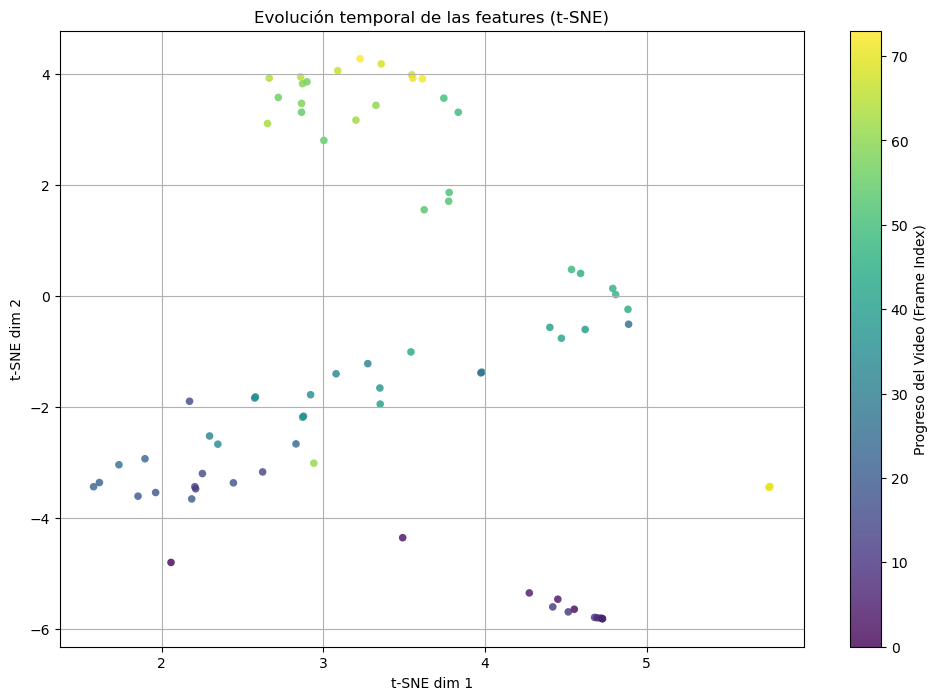

In [11]:
i = 40
filename, x, mask, y = dataset[i]
tsne = TSNE(n_components=2, perplexity=30.0, learning_rate='auto', init='pca', random_state=SEED)
# Ajustar y transformar los datos
vis_dims = tsne.fit_transform(x[mask == 1])
plot_tsne(vis_dims)

In [48]:
#concatenate two arrays
dataset_dict = {"files": [], "features": [], "mask": [], "label": [], 'index': []}
for i, (file, features, mask, label) in enumerate(dataset):
    if i!= 281:
        dataset_dict["files"].append(file)
        dataset_dict["features"].append(features[mask == 1])
        dataset_dict["index"].append([i for i in range(len(features)) if mask[i] == 1])
        dataset_dict["mask"].append(mask)
        dataset_dict["label"].append(label)
all_features = np.concatenate(dataset_dict["features"], axis=0)
all_features = all_features.reshape(-1, 512)

In [49]:
vis_dims = tsne.fit_transform(all_features)

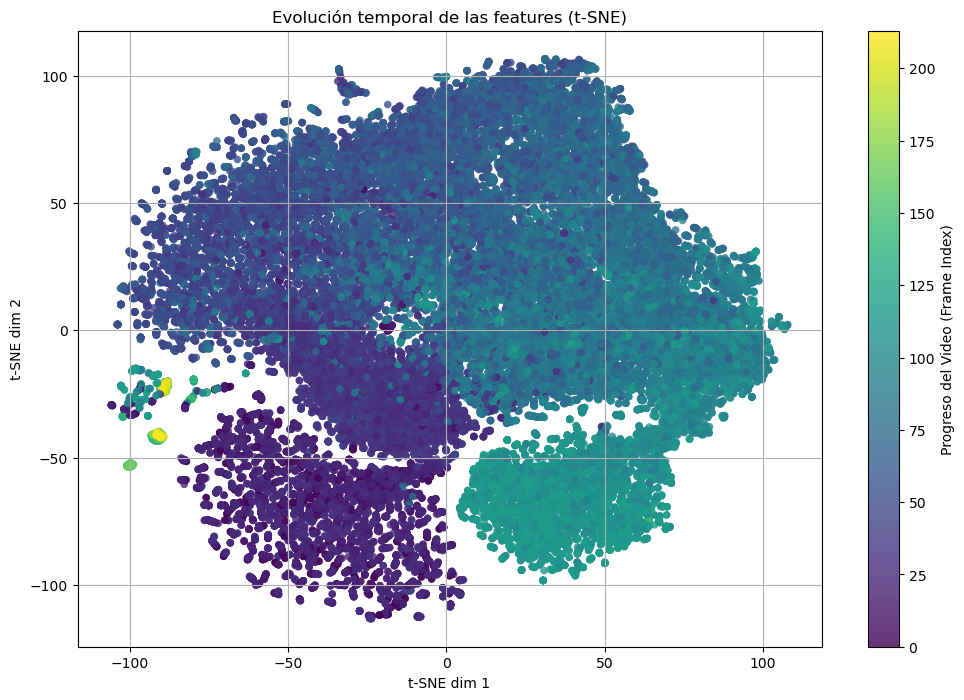

In [50]:
index = np.concatenate(dataset_dict["index"], axis=0)
plot_tsne(vis_dims, color=True, index = index)

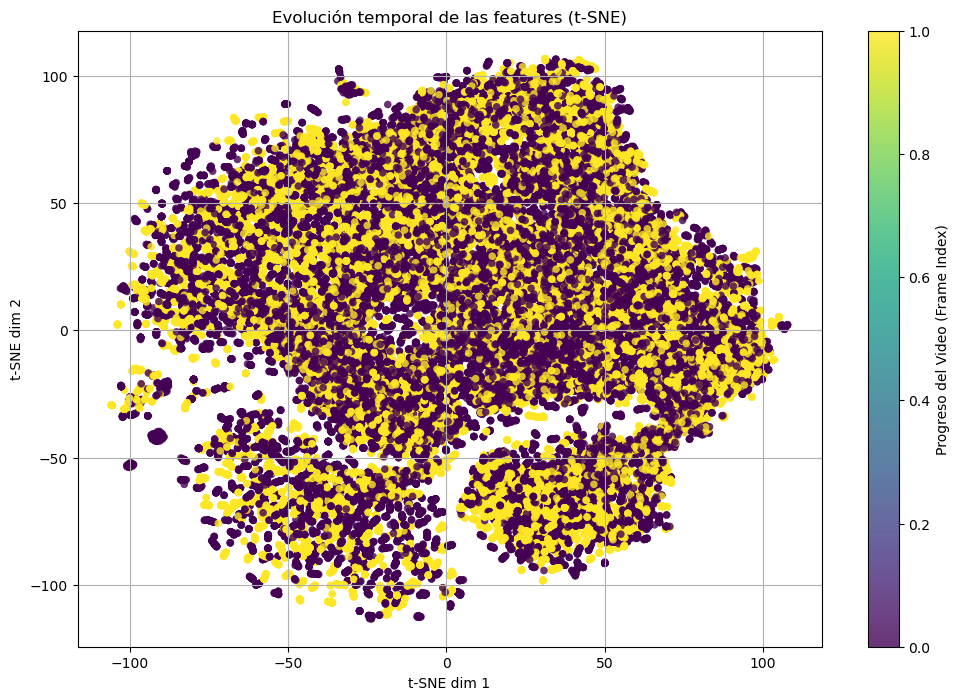

In [51]:
lbl = [[dataset_dict["label"][i] for _ in dataset_dict["features"][i]] for i in range(len(dataset_dict["label"]))]
labels = np.concatenate(lbl, axis=0)
plot_tsne(vis_dims, color=True, index = labels)

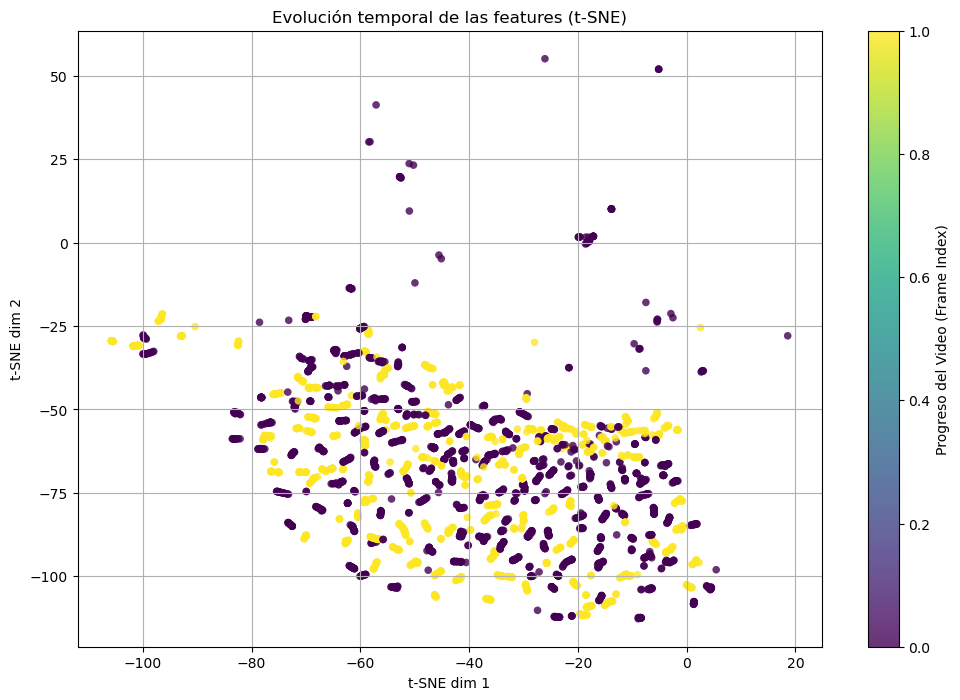

In [55]:
plot_tsne(vis_dims[index < 19], color=True, index = labels[index < 19])

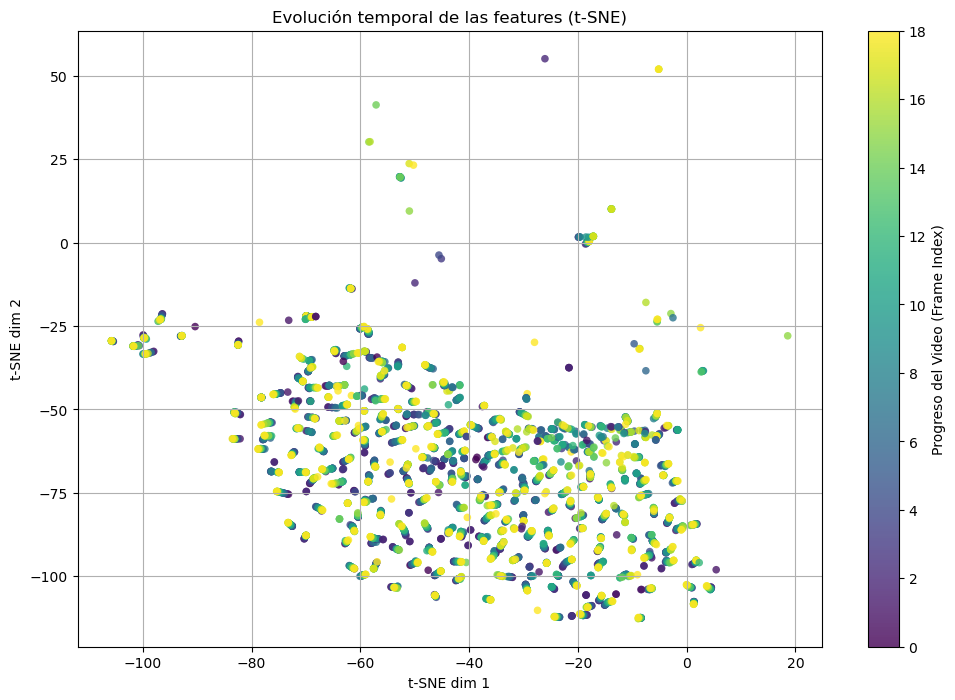

In [56]:
plot_tsne(vis_dims[index < 19], color=True, index = index[index < 19])

In [57]:
t = 29
puntos = vis_dims[index <= t]
sub_index = index[index <= t]
sub_lbl = labels[index <= t]

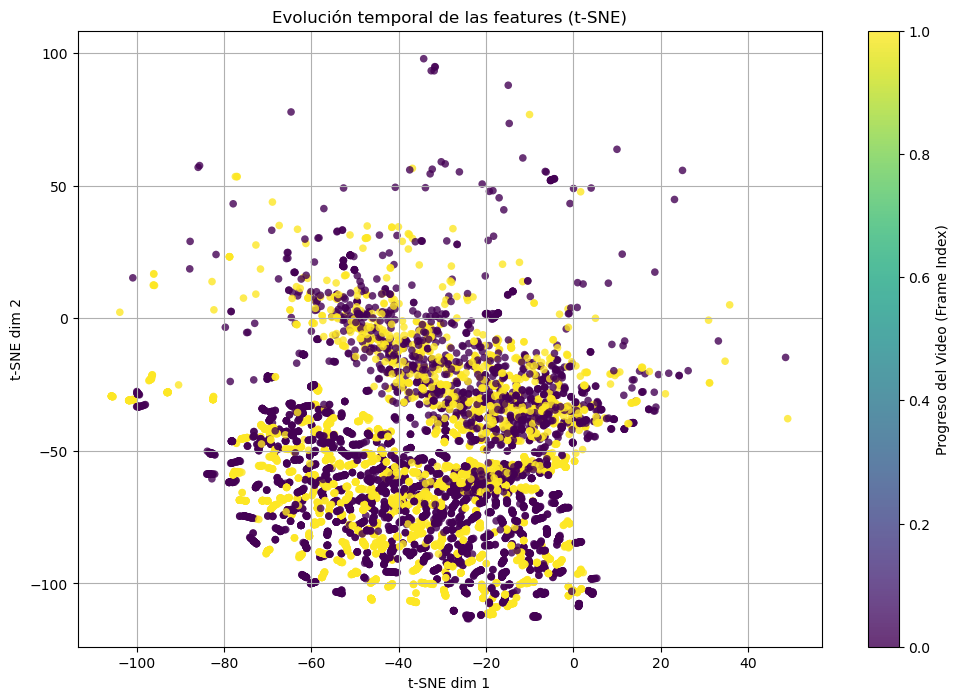

In [58]:
plot_tsne(puntos, color=True, index = sub_lbl)

### Latent velocity

In [59]:
dataset_dict.keys()

dict_keys(['files', 'features', 'mask', 'label', 'index'])

In [60]:
dataset_dict['latent_velocities'] = []
for i in range(len(dataset_dict["features"])):
    dataset_dict['latent_velocities'].append([])
    distance = np.diff(dataset_dict["features"][i], axis=0)
    dataset_dict['latent_velocities'][-1] = np.linalg.norm(distance, axis=1)
dataset_dict['variance_velocities'] = [np.var(velocities) for velocities in dataset_dict['latent_velocities']]

In [61]:
dataset_dict['label'] = np.array(dataset_dict['label'])
dataset_dict['variance_velocities'] = np.array(dataset_dict['variance_velocities'])

In [62]:
var_0 = dataset_dict['variance_velocities'][dataset_dict['label'] == 0]
var_1 = dataset_dict['variance_velocities'][dataset_dict['label'] == 1]

np.mean(var_0), np.mean(var_1)

(np.float32(12.856866), np.float32(12.955799))

In [63]:
np.std(var_0), np.std(var_1)

(np.float32(3.552608), np.float32(3.0603))

11:13:56 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
11:13:56 | INFO     | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


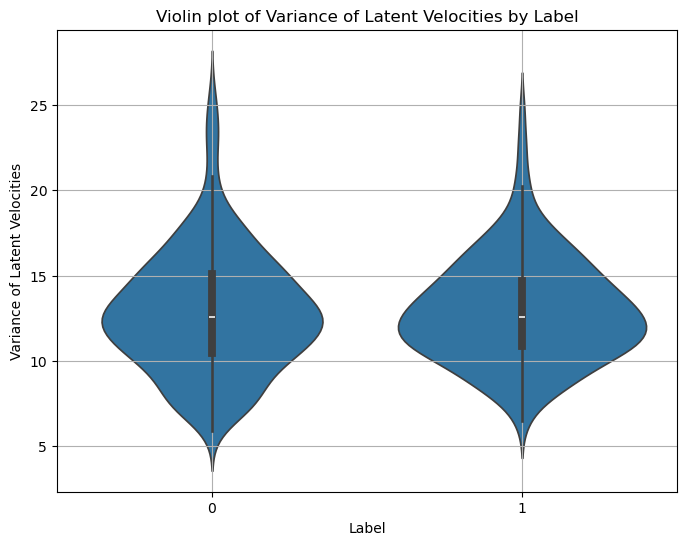

In [64]:
# violin plot
plt.figure(figsize=(8, 6))
sns.violinplot(x=dataset_dict['label'], y=dataset_dict['variance_velocities'])
plt.xlabel('Label')
plt.ylabel('Variance of Latent Velocities')
plt.title('Violin plot of Variance of Latent Velocities by Label')
plt.grid(True)
plt.show()

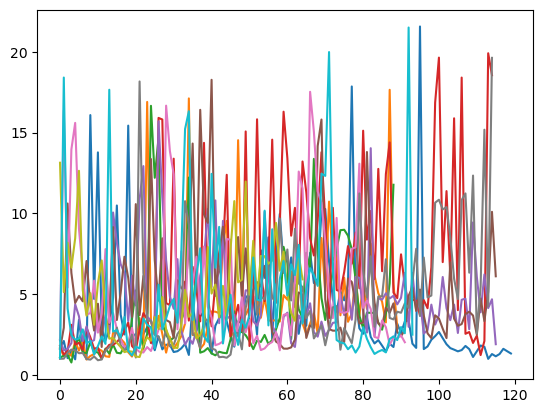

In [65]:
for i in range(10):
    plt.plot(dataset_dict['latent_velocities'][i])

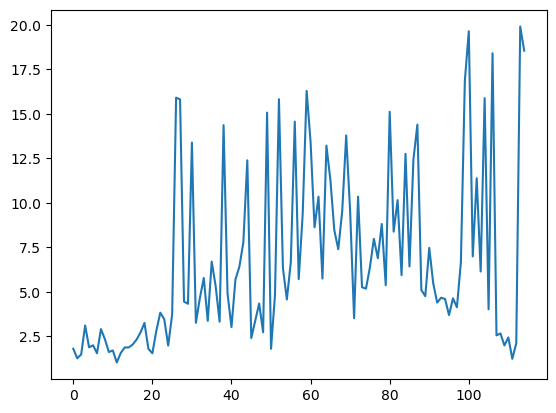

In [66]:
plt.plot(dataset_dict['latent_velocities'][3])

In [122]:
#TIME SERIES KMEANS
from tslearn.clustering import TimeSeriesKMeans
km = TimeSeriesKMeans(
    n_clusters=2,
    metric="euclidean",  # Options: "euclidean", "dtw", "softdtw"
    max_iter=10,
    metric_params={"gamma": .05},
    verbose=True,
    random_state=SEED
)

In [123]:
embedded_velocities = np.zeros_like(dataset_dict['mask']).astype(float)

for i in range(len(embedded_velocities)):
    mask_indices = np.where(dataset_dict['mask'][i] == 1)[0]
    if len(mask_indices) > 0:
        target_indices = mask_indices[:-1]
        embedded_velocities[i, target_indices] = dataset_dict['latent_velocities'][i]

In [124]:
y_pred = km.fit_predict(embedded_velocities)

2115.733 --> 1253.975 --> 1237.802 --> 1237.575 --> 1237.539 --> 1237.539 --> 


In [125]:
#compute accuracy, classification report and confusion matrix
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(dataset_dict['label'], y_pred)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(dataset_dict['label'], y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(dataset_dict['label'], y_pred))

Accuracy: 0.5400

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.69      0.64       265
           1       0.42      0.33      0.37       185

    accuracy                           0.54       450
   macro avg       0.51      0.51      0.50       450
weighted avg       0.52      0.54      0.53       450


Confusion Matrix:
[[182  83]
 [124  61]]


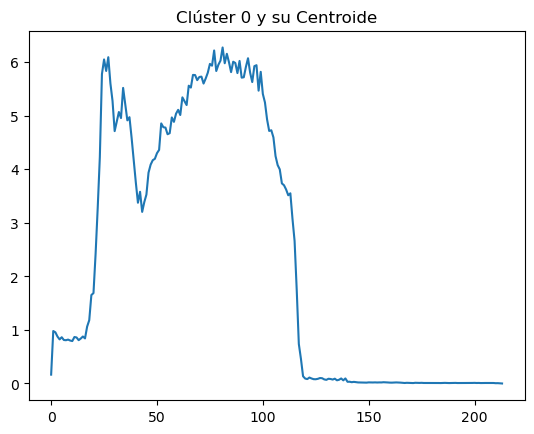

In [126]:
cluster_idx = 0
plt.plot(km.cluster_centers_[cluster_idx].ravel())
plt.title(f"Clúster {cluster_idx} y su Centroide")
plt.show()

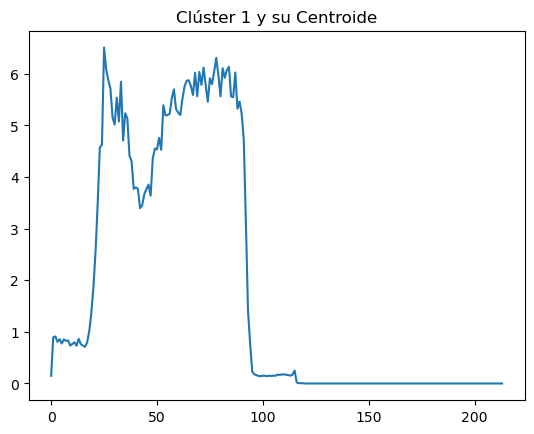

In [127]:
cluster_idx = 1
plt.plot(km.cluster_centers_[cluster_idx].ravel())
plt.title(f"Clúster {cluster_idx} y su Centroide")
plt.show()

In [133]:
dbscan = DBSCAN(eps=5, min_samples=5).fit(puntos)
labels = dbscan.labels_

In [152]:
np.unique(sub_lbl[puntos[:,0] > 0], return_counts=True)

(array([0, 1]), array([66, 35]))

In [153]:
np.unique(sub_lbl[puntos[:,1] > 0], return_counts=True)

(array([0]), array([49]))

In [154]:
path_v = sub_paths[puntos[:,1] > 0]
index_v = sub_index[puntos[:,1] > 0]

In [160]:
str(path_v[0])

'D2018.10.19_S01228_I0426_D_Well_04.avi'

IndexError: index 49 is out of bounds for axis 0 with size 49

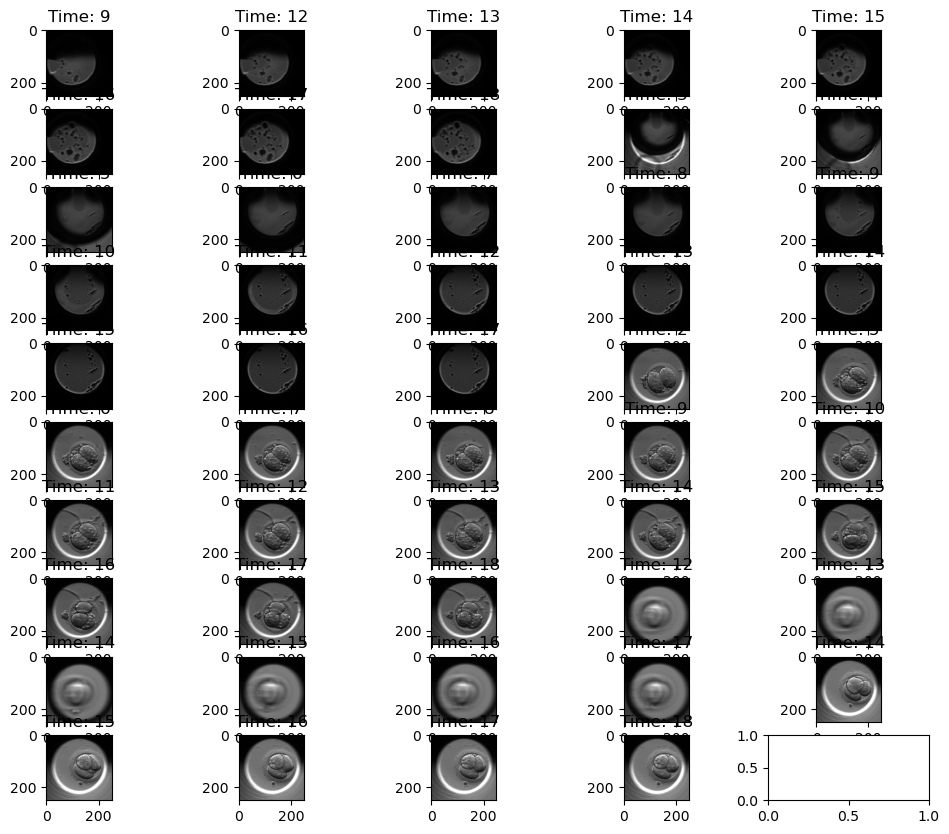

In [161]:
fig, axes = plt.subplots(10,5, figsize=(12, 10))
axes = axes.flatten()
for i in range(50):
    axes[i].imshow(image_frame(str(path_v[i]), excel_path, t=index_v[i]))
    axes[i].set_title(f"Time: {index_v[i]}")
plt.tight_layout()
plt.show()

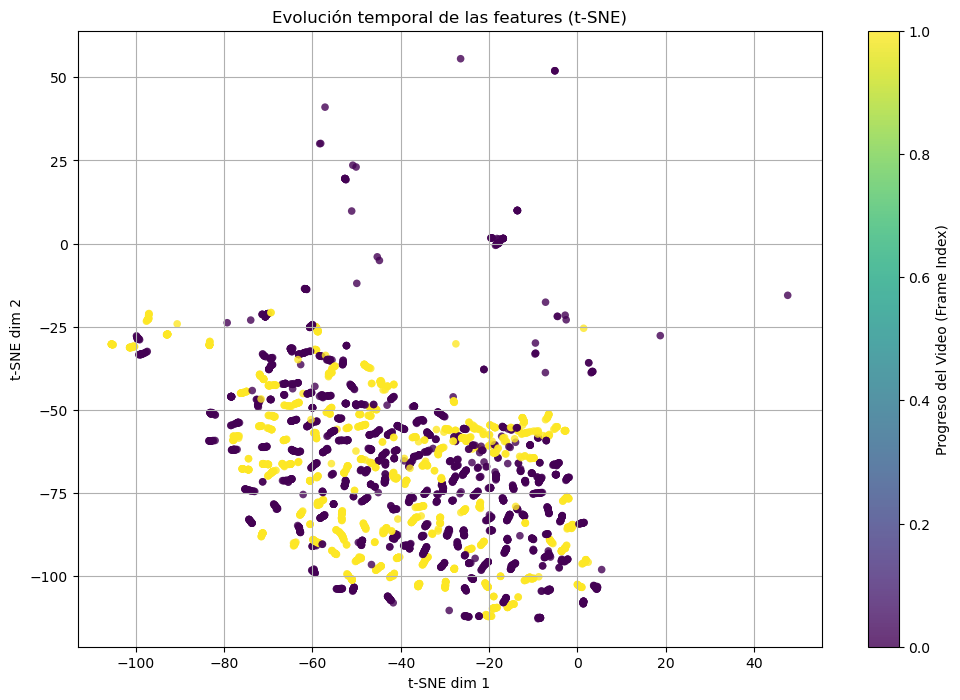

In [ ]:
plot_tsne(puntos, color=True, index = sub_lbl)

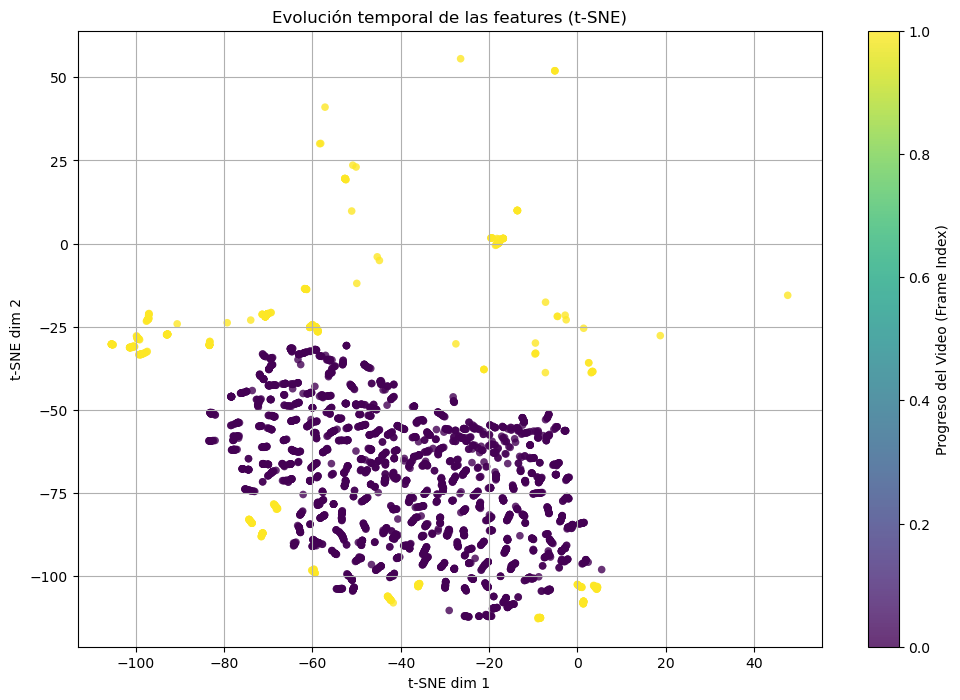

In [136]:
plot_tsne(puntos, color=True, index = labels != 0)

In [ ]:
plt.imshow(image_frame(paths[0], excel_path, t=0))

../Datasets/Processed/Oslo_processed/videos/D2016.05.14_S0631_I426_Well_04.avi


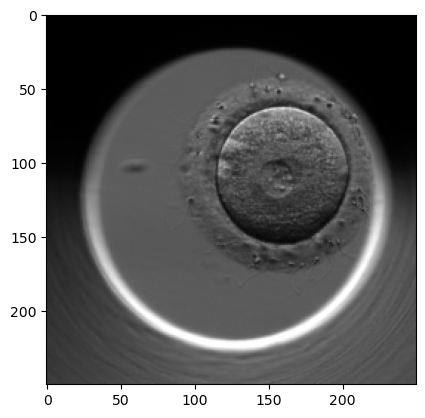

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(12, 5))
axes = axes.flatten()
for i in range(10):
    axes[i].imshow(image_frame(frames['files'][i], excel_path, t=121))
    axes[i].set_title(f"Cluster: {frames['clusters'][i]}")
plt.tight_layout()
plt.show()